# 📊 Cuaderno de datos: ¿la Skill `revisar-codigo` mejora a Gemini?

**Proyecto:** Skill para Gemini aplicada a la Ingeniería Informática
**Curso:** Ingeniería Informática — tercer semestre (2026)

## Objetivo
Medir con datos si nuestra Skill `revisar-codigo` hace que Gemini revise código mejor que cuando se le pide lo mismo sin la Skill.

## ¿De dónde salen los datos?
1. Escribimos **10 programas cortos** (Python, Java, JavaScript, C y SQL) y les metimos **24 errores a propósito** (`pruebas/errores_esperados.csv`). El caso 7 no tiene errores: sirve para ver si la IA inventa problemas.
2. Le pedimos a Gemini (modo Pro, gemini.google.com) en un **chat nuevo por caso**: `Revisa este codigo y dime que errores tiene:` + el código.
3. Lo hicimos **dos veces**: primero **sin la Skill** (línea base) y después **con la Skill activa**, sin nombrarla (para ver si se activa sola).
4. Leímos cada respuesta y anotamos qué errores encontró, el tiempo de respuesta y si usó severidad, número de línea y la plantilla.

Las respuestas completas están en `pruebas/respuestas/`.

## Preguntas que queremos responder
- **P1.** ¿Con la Skill se detectan más errores?
- **P2.** ¿En qué tipo de errores ayuda más?
- **P3.** ¿La Skill hace las respuestas más ordenadas (severidad, línea, plantilla)?
- **P4.** ¿Cuánto tiempo extra cuesta?
- **P5.** ¿Las severidades que pone la Skill coinciden con las que esperábamos?

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Colores fijos para cada modo (el mismo color siempre significa lo mismo)
COLOR_CON = "#2a78d6"   # con Skill
COLOR_SIN = "#eb6834"   # sin Skill
GRIS = "#b9b8b2"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "font.size": 10,
})

# Si el cuaderno se abre en Google Colab, los CSV se leen directo desde GitHub
REPO_RAW = "https://raw.githubusercontent.com/nicolasravem-design/skill-revisor-codigo-gemini/main/pruebas/"
CARPETA = "../pruebas/" if os.path.exists("../pruebas/resultados_por_caso.csv") else REPO_RAW
os.makedirs("graficas", exist_ok=True)

resultados = pd.read_csv(CARPETA + "resultados_por_caso.csv")
errores = pd.read_csv(CARPETA + "deteccion_por_error.csv")
print("Datos leídos desde:", CARPETA)
print("resultados:", resultados.shape, "| errores:", errores.shape)

Datos leídos desde: ../pruebas/
resultados: (20, 15) | errores: (24, 8)


## 1. Exploración de los datos

In [2]:
resultados.head(12)

,modo,caso,archivo,lenguaje,tiempo_s,errores_esperados,errores_detectados,falsos_positivos,hallazgos_reportados,usa_severidad,cita_lineas,codigo_corregido,sigue_plantilla,calificacion,veredicto
0,sin_skill,1,caso01_promedio.py,Python,14.2,2,2,0,2,0,0,1,0,NaN,NaN
1,sin_skill,2,caso02_login.py,Python,28.8,3,3,0,4,0,0,1,0,NaN,NaN
2,sin_skill,3,caso03_Busqueda.java,Java,29.3,2,2,0,2,0,0,0,0,NaN,NaN
3,sin_skill,4,caso04_carrito.js,JavaScript,30.6,3,2,0,4,0,0,1,0,NaN,NaN
4,sin_skill,5,caso05_duplicados.py,Python,24.9,1,1,0,2,0,0,1,0,NaN,NaN
5,sin_skill,6,caso06_nombre.c,C,59.2,4,4,0,4,0,0,1,0,NaN,NaN
6,sin_skill,7,caso07_primo.py,Python,15.4,0,0,0,0,0,0,1,0,NaN,NaN
7,sin_skill,8,caso08_estudiantes.sql,SQL,29.3,2,1,0,1,0,0,1,0,NaN,NaN
8,sin_skill,9,caso09_Cuenta.java,Java,33.8,4,2,0,4,0,0,1,0,NaN,NaN
9,sin_skill,10,caso10_usuario.js,JavaScript,25.1,3,2,0,2,0,0,1,0,NaN,NaN


In [3]:
errores.head()

,error_id,caso,lenguaje,categoria,severidad_esperada,detectado_sin_skill,detectado_con_skill,severidad_dada_con_skill
0,1-A,1,Python,Bug,Critico,1,1,Critico
1,1-B,1,Python,Bug,Alto,1,1,Critico
2,2-A,2,Python,Seguridad,Critico,1,1,Critico
3,2-B,2,Python,Seguridad,Alto,1,0,NaN
4,2-C,2,Python,Buenas practicas,Medio,1,1,Medio


In [4]:
# Revisión rápida: ¿faltan datos? (las columnas calificacion/veredicto solo existen con la Skill)
resultados.isna().sum()

modo                     0
caso                     0
archivo                  0
lenguaje                 0
tiempo_s                 0
errores_esperados        0
errores_detectados       0
falsos_positivos         0
hallazgos_reportados     0
usa_severidad            0
cita_lineas              0
codigo_corregido         0
sigue_plantilla          0
calificacion            10
veredicto               10
dtype: int64

## 2. P1 — ¿Con la Skill se detectan más errores?
La métrica principal es la **tasa de detección** (en inglés *recall*):

$$\text{tasa de detección} = \frac{\text{errores detectados}}{\text{errores sembrados}}$$

In [5]:
resumen = resultados.groupby("modo").agg(
    errores_esperados=("errores_esperados", "sum"),
    errores_detectados=("errores_detectados", "sum"),
    falsos_positivos=("falsos_positivos", "sum"),
    tiempo_promedio_s=("tiempo_s", "mean"),
    con_severidad=("usa_severidad", "sum"),
    con_linea=("cita_lineas", "sum"),
    con_plantilla=("sigue_plantilla", "sum"),
)
resumen["tasa_deteccion_%"] = (resumen["errores_detectados"] / resumen["errores_esperados"] * 100).round(1)
resumen = resumen.loc[["sin_skill", "con_skill"]]
resumen.round(2)

,errores_esperados,errores_detectados,falsos_positivos,tiempo_promedio_s,con_severidad,con_linea,con_plantilla,tasa_deteccion_%
modo,,,,,,,,
sin_skill,24,19,0,29.06,0,0,0,79.2
con_skill,24,22,0,35.49,10,10,10,91.7


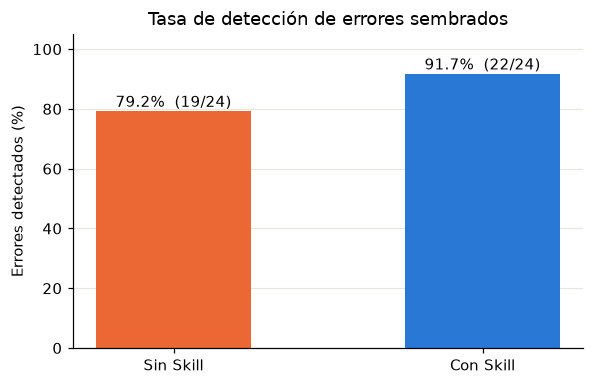

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
modos = ["Sin Skill", "Con Skill"]
tasas = resumen["tasa_deteccion_%"].values
barras = ax.bar(modos, tasas, color=[COLOR_SIN, COLOR_CON], width=0.5)
for b, valor, det in zip(barras, tasas, resumen["errores_detectados"]):
    ax.text(b.get_x() + b.get_width() / 2, valor + 1.5, f"{valor:.1f}%  ({det}/24)", ha="center")
ax.set_ylim(0, 105)
ax.set_ylabel("Errores detectados (%)")
ax.set_title("Tasa de detección de errores sembrados")
plt.tight_layout()
plt.savefig("graficas/01_tasa_deteccion.png")
plt.show()

### Detección por caso

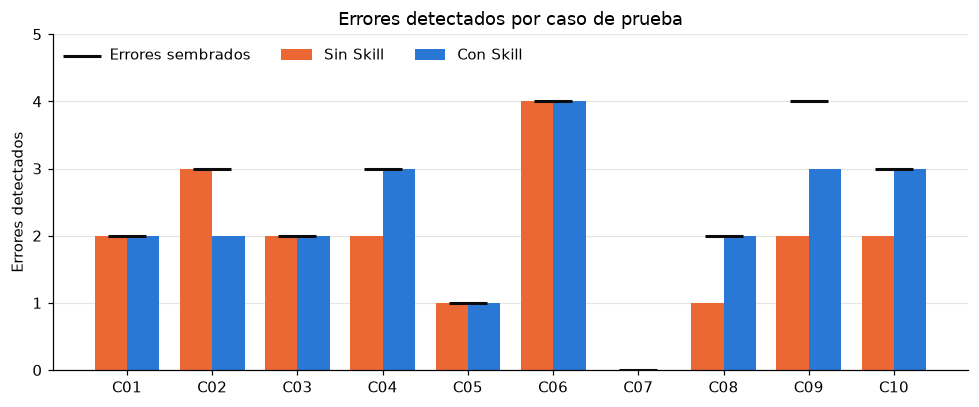

modo,con_skill,sin_skill,esperados
C01,2,2,2
C02,2,3,3
C03,2,2,2
C04,3,2,3
C05,1,1,1
C06,4,4,4
C07,0,0,0
C08,2,1,2
C09,3,2,4
C10,3,2,3


In [7]:
por_caso = resultados.pivot(index="caso", columns="modo", values="errores_detectados")
por_caso["esperados"] = resultados.groupby("caso")["errores_esperados"].first()
por_caso.index = [f"C{c:02d}" for c in por_caso.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(por_caso))
ancho = 0.38
ax.bar([i - ancho / 2 for i in x], por_caso["sin_skill"], ancho, label="Sin Skill", color=COLOR_SIN)
ax.bar([i + ancho / 2 for i in x], por_caso["con_skill"], ancho, label="Con Skill", color=COLOR_CON)
ax.scatter(list(x), por_caso["esperados"], marker="_", s=600, color="#0b0b0b", linewidths=2, label="Errores sembrados", zorder=3)
ax.set_xticks(list(x))
ax.set_xticklabels(por_caso.index)
ax.set_ylabel("Errores detectados")
ax.set_title("Errores detectados por caso de prueba")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_ylim(0, 5)
plt.tight_layout()
plt.savefig("graficas/02_deteccion_por_caso.png")
plt.show()
por_caso

**Lectura:** con la Skill se iguala o mejora la línea base en 9 de 10 casos. El único caso donde empeora es el **C02** (login con SQL): la Skill no mencionó que la contraseña se compara en texto plano.

## 3. P2 — ¿En qué tipo de errores ayuda más?

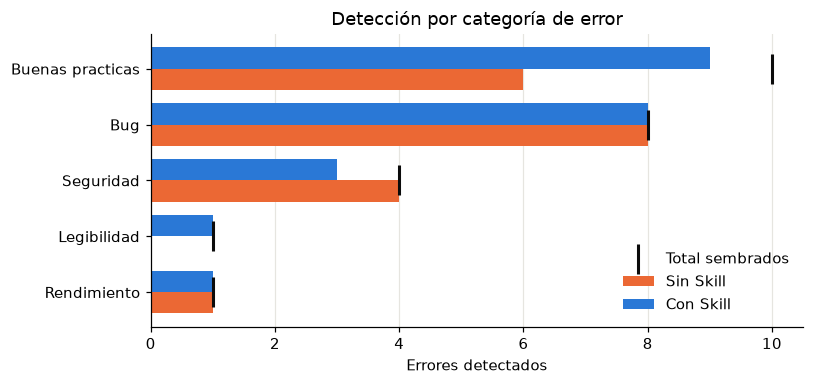

,detectado_sin_skill,detectado_con_skill,total
categoria,,,
Rendimiento,1,1,1
Legibilidad,0,1,1
Seguridad,4,3,4
Bug,8,8,8
Buenas practicas,6,9,10


In [8]:
por_categoria = errores.groupby("categoria")[["detectado_sin_skill", "detectado_con_skill"]].sum()
por_categoria["total"] = errores.groupby("categoria").size()
por_categoria = por_categoria.sort_values("total", ascending=True)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = range(len(por_categoria))
alto = 0.38
ax.barh([i - alto / 2 for i in y], por_categoria["detectado_sin_skill"], alto, color=COLOR_SIN, label="Sin Skill")
ax.barh([i + alto / 2 for i in y], por_categoria["detectado_con_skill"], alto, color=COLOR_CON, label="Con Skill")
ax.scatter(por_categoria["total"], list(y), marker="|", s=400, color="#0b0b0b", linewidths=2, label="Total sembrados", zorder=3)
ax.set_yticks(list(y))
ax.set_yticklabels(por_categoria.index)
ax.set_xlabel("Errores detectados")
ax.set_title("Detección por categoría de error")
ax.grid(axis="x", color="#e6e5e0")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("graficas/03_deteccion_por_categoria.png")
plt.show()
por_categoria

In [9]:
# ¿Qué errores encontró SOLO un modo?
solo_con = errores[(errores.detectado_con_skill == 1) & (errores.detectado_sin_skill == 0)]
solo_sin = errores[(errores.detectado_sin_skill == 1) & (errores.detectado_con_skill == 0)]
ninguno = errores[(errores.detectado_sin_skill == 0) & (errores.detectado_con_skill == 0)]

print("Solo con la Skill:", list(solo_con.error_id))
print("Solo sin la Skill:", list(solo_sin.error_id))
print("Ninguno de los dos:", list(ninguno.error_id))

Solo con la Skill: ['4-B', '8-B', '9-D', '10-C']
Solo sin la Skill: ['2-B']
Ninguno de los dos: ['9-C']


In [10]:
esperados = pd.read_csv(CARPETA + "errores_esperados.csv")
diferencias = esperados[esperados.error_id.isin(list(solo_con.error_id) + list(solo_sin.error_id) + list(ninguno.error_id))]
diferencias[["error_id", "lenguaje", "categoria", "descripcion"]]

,error_id,lenguaje,categoria,descripcion
3,2-B,Python,Seguridad,La clave se guarda y compara en texto plano (s...
8,4-B,JavaScript,Legibilidad,Numeros magicos 100000 y 0.9 sin constante con...
16,8-B,SQL,Buenas practicas,SELECT * trae columnas innecesarias
19,9-C,Java,Buenas practicas,Usar double para dinero produce errores de red...
20,9-D,Java,Buenas practicas,El Scanner nunca se cierra
23,10-C,JavaScript,Buenas practicas,La promesa no tiene .catch()


**Lectura:** la Skill ayuda sobre todo en **buenas prácticas y legibilidad** (números mágicos, `SELECT *`, `Scanner` sin cerrar, promesa sin `.catch()`): son cosas que un revisor humano anota pero que Gemini "normal" suele omitir. La checklist de la Skill lo obliga a revisarlas. En **bugs** ambos modos encuentran los 8. En **seguridad** la Skill quedó 1 por debajo (3 de 4): no mencionó la contraseña en texto plano del caso 2, algo que hay que agregar a la checklist.

## 4. P3 — ¿Las respuestas son más ordenadas?

In [11]:
formato = resultados.groupby("modo")[["usa_severidad", "cita_lineas", "codigo_corregido", "sigue_plantilla"]].mean() * 100
formato = formato.loc[["sin_skill", "con_skill"]].round(0)
formato.columns = ["Usa severidad (%)", "Cita número de línea (%)", "Incluye código corregido (%)", "Sigue la plantilla (%)"]
formato

,Usa severidad (%),Cita número de línea (%),Incluye código corregido (%),Sigue la plantilla (%)
modo,,,,
sin_skill,0.0,0.0,90.0,0.0
con_skill,100.0,100.0,100.0,100.0


Con la Skill, **10 de 10** respuestas tuvieron la misma estructura (Resumen → Hallazgos → Código corregido → Lo que está bien → Para aprender más), con severidad y número de línea. Además la Skill **se activó sola** en los 10 casos, solo por la descripción.

En el caso de control (C07, sin errores) la Skill respondió `✅ Aprobado 10/10` con la tabla vacía: **no inventó errores**. Falsos positivos totales: 0 en ambos modos.

## 5. P4 — ¿Cuánto tiempo extra cuesta?

modo  con_skill  sin_skill  diferencia_s
mean       35.5       29.1           6.4
50%        32.7       29.0           4.8
min        24.2       14.2         -11.9
max        49.5       59.2          27.4


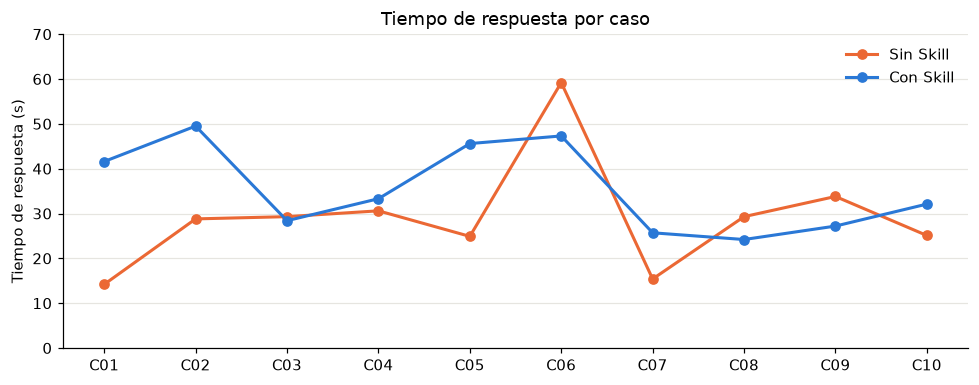

In [12]:
tiempos = resultados.pivot(index="caso", columns="modo", values="tiempo_s")
tiempos["diferencia_s"] = tiempos["con_skill"] - tiempos["sin_skill"]
print(tiempos.describe().round(1).loc[["mean", "50%", "min", "max"]])

fig, ax = plt.subplots(figsize=(9, 3.6))
casos = [f"C{c:02d}" for c in tiempos.index]
ax.plot(casos, tiempos["sin_skill"], marker="o", markersize=6, linewidth=2, color=COLOR_SIN, label="Sin Skill")
ax.plot(casos, tiempos["con_skill"], marker="o", markersize=6, linewidth=2, color=COLOR_CON, label="Con Skill")
ax.set_ylabel("Tiempo de respuesta (s)")
ax.set_title("Tiempo de respuesta por caso")
ax.legend(frameon=False)
ax.set_ylim(0, 70)
plt.tight_layout()
plt.savefig("graficas/04_tiempos.png")
plt.show()

In [13]:
# ¿Los casos con más errores tardan más? (correlación de Pearson)
for modo in ["sin_skill", "con_skill"]:
    datos = resultados[resultados.modo == modo]
    r = datos["tiempo_s"].corr(datos["errores_esperados"])
    print(f"{modo}: correlación tiempo vs. errores sembrados = {r:.2f}")

sin_skill: correlación tiempo vs. errores sembrados = 0.70
con_skill: correlación tiempo vs. errores sembrados = 0.23


**Lectura:** la Skill tarda en promedio unos **6 segundos más** porque escribe una respuesta más completa (tabla, código, sección de aprendizaje). Es un costo pequeño para una revisión más ordenada. Ojo: el tiempo también depende de la carga de los servidores de Gemini, así que con solo 10 casos la diferencia no es concluyente.

## 6. P5 — ¿Las severidades coinciden con las esperadas?

Severidad igual a la esperada: 14 de 22 (64%)


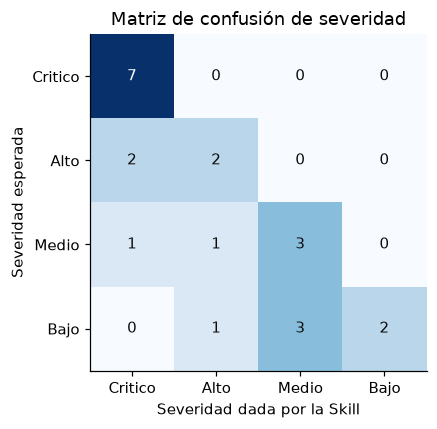

Dada por la Skill,Critico,Alto,Medio,Bajo
Esperada,,,,
Critico,7,0,0,0
Alto,2,2,0,0
Medio,1,1,3,0
Bajo,0,1,3,2


In [14]:
orden = ["Critico", "Alto", "Medio", "Bajo"]
detectados = errores[errores.detectado_con_skill == 1].copy()
matriz = pd.crosstab(
    pd.Categorical(detectados.severidad_esperada, categories=orden),
    pd.Categorical(detectados.severidad_dada_con_skill, categories=orden),
    dropna=False,
)
matriz.index.name = "Esperada"
matriz.columns.name = "Dada por la Skill"

aciertos = (detectados.severidad_esperada == detectados.severidad_dada_con_skill).sum()
print(f"Severidad igual a la esperada: {aciertos} de {len(detectados)} ({aciertos / len(detectados):.0%})")

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(matriz.values, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(orden)
ax.set_yticks(range(4)); ax.set_yticklabels(orden)
ax.set_xlabel("Severidad dada por la Skill")
ax.set_ylabel("Severidad esperada")
ax.set_title("Matriz de confusión de severidad")
ax.grid(False)
for i in range(4):
    for j in range(4):
        valor = matriz.values[i, j]
        ax.text(j, i, valor, ha="center", va="center", color="white" if valor > 3 else "#0b0b0b")
plt.tight_layout()
plt.savefig("graficas/05_matriz_severidad.png")
plt.show()
matriz

**Lectura:** la diagonal son los aciertos. Todos los errores que esperábamos como **Crítico** los marcó como Crítico, pero la Skill tiende a **subir la severidad** de los demás: todo lo que está fuera de la diagonal queda a la izquierda de ella, es decir, en un nivel más grave que el esperado (nunca bajó una severidad). Para un estudiante esto no es grave (prefiere que le avisen de más), pero se puede mejorar agregando ejemplos de cada nivel en el `SKILL.md`.

## 7. Conclusiones

| Pregunta | Respuesta corta |
|---|---|
| P1 ¿Detecta más errores? | **Sí:** 22/24 (91.7 %) con Skill vs. 19/24 (79.2 %) sin Skill. |
| P2 ¿Dónde ayuda más? | En **buenas prácticas y legibilidad**; en bugs ambos modos ya eran buenos. |
| P3 ¿Respuestas más ordenadas? | **Sí:** 10/10 con plantilla, severidad y línea; se activó sola 10/10 y 0 falsos positivos. |
| P4 ¿Costo en tiempo? | ~6 s más en promedio (35.5 s vs. 29.1 s). |
| P5 ¿Severidad correcta? | 14 de 22 coinciden; tiende a exagerar la gravedad. |

**Mejoras para la versión 2 de la Skill:**
1. Agregar a la checklist de seguridad: *"contraseñas guardadas o comparadas en texto plano"*.
2. Agregar *"usar `double`/`float` para dinero"* a la checklist de Java.
3. Poner un ejemplo por nivel de severidad para calibrarla.

**Limitaciones:** pocos casos (10), programas cortos, una sola ejecución por caso y evaluación manual hecha por nosotros. Los resultados son una primera evidencia, no una prueba estadística.